# Notebook #04 — Classification (3-Class Primary + Binary & Horizon Ablations) & L1/MAE Regression

### Các thực nghiệm đã huấn luyện & so sánh
- **Classification 3 lớp ICAO (`on_time / delayed / cancelled`, `T-3h`):** `MajorityClassifier`, `HeuristicBaseline`, `HistGradientBoosting`, `XGBoost`, `CatBoost` (tuyển chọn theo **Validation `f1_macro`**).
- **Binary Ablation (`on_time` vs `disrupted`):** Đánh giá khả năng phân tách khi gom trễ & hủy.
- **Horizon Sensitivity (`T-1h`, `T-3h`, `T-6h`):** Đo lường thay đổi dự báo khi dịch mốc nhân quả `prediction_time`.
- **L1/MAE Regression (`delay_min`):** Chỉ huấn luyện trên chuyến hoàn tất (`9,414` train / `1,339` val / `2,711` test), loại bỏ hoàn toàn chuyến hủy.

In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

cls = json.loads(Path("reports/experiments/classification_results.json").read_text(encoding="utf-8"))
reg = json.loads(Path("reports/experiments/regression_results.json").read_text(encoding="utf-8"))

mc = cls["multiclass_3"]
bn = cls["binary_disrupted"]
print(f"Primary 3-Class Winner (Val f1_macro): {mc['best_model']}")
df_mc = pd.DataFrame(mc["test_comparison"]).T[["accuracy", "balanced_accuracy", "f1_macro", "delayed_recall", "cancelled_recall", "roc_auc_ovr", "pr_auc_macro", "log_loss"]]
print("\n=== Holdout Test 3-Class Comparison ===")
print(df_mc.round(4).to_string())

print("\n=== Horizon Sensitivity Ablation (T-1h / T-3h / T-6h) ===")
print(pd.DataFrame(cls["horizon_ablation"]["horizons"]).to_string(index=False))

print(f"\n=== Regression MAE Comparison (Best: {reg['best_model']}) ===")
print(pd.DataFrame(reg["test_comparison"]).T[["MAE_minutes", "MedAE_minutes", "RMSE_minutes", "R2_Score"]].to_string())

Primary 3-Class Winner (Val f1_macro): CatBoost

=== Holdout Test 3-Class Comparison ===
                     accuracy balanced_accuracy f1_macro delayed_recall cancelled_recall roc_auc_ovr pr_auc_macro log_loss
MajorityClassifier     0.7992            0.3333   0.2961            0.0              0.0         0.5       0.3333   7.2379
HeuristicBaseline      0.7369            0.3713   0.3733          0.256              0.0      0.7058       0.3666   0.5833
HistGradientBoosting   0.7668            0.3994    0.404         0.3186              0.0      0.8012       0.7516   0.4898
XGBoost                0.7568            0.4187   0.4174         0.4125              0.0      0.8045       0.7557   0.5026
CatBoost               0.7498            0.4186   0.4154         0.4236              0.0      0.8082       0.5402    0.517

=== Horizon Sensitivity Ablation (T-1h / T-3h / T-6h) ===
 horizon_hours  is_primary best_algorithm  val_f1_macro  test_f1_macro  test_balanced_accuracy  test_delayed_recal

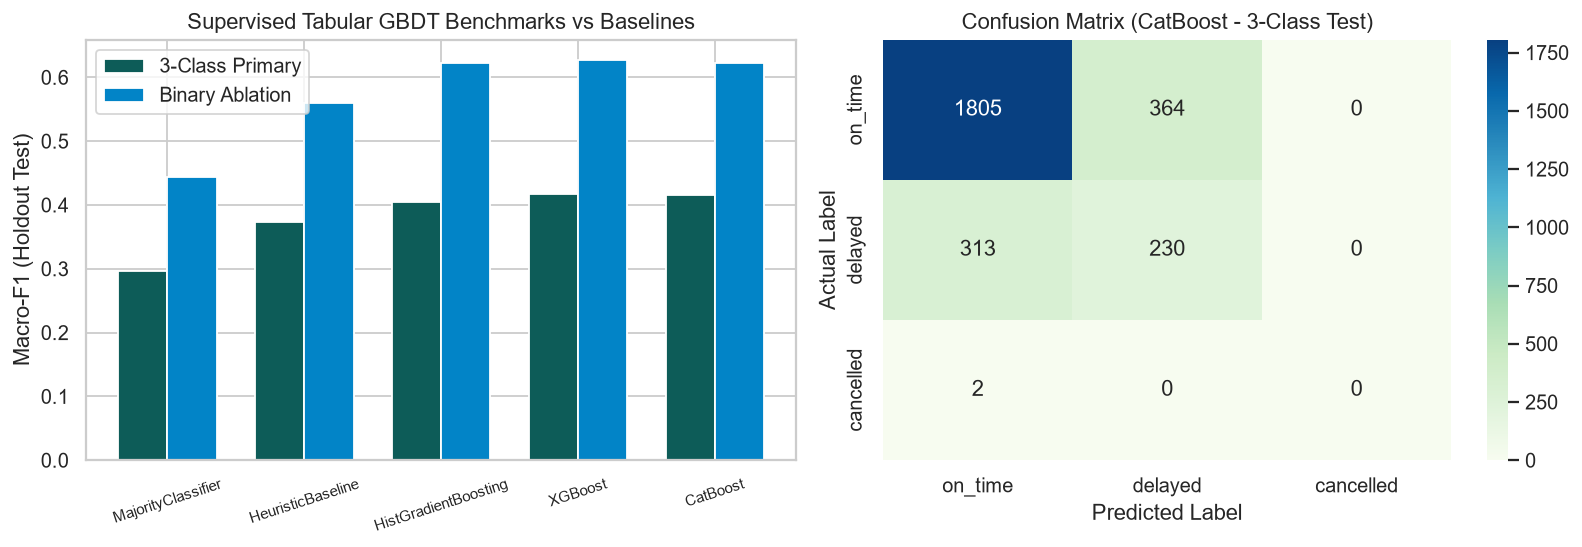

In [2]:
# Model Comparison & Confusion Matrix Plots
models = ["MajorityClassifier", "HeuristicBaseline", "HistGradientBoosting", "XGBoost", "CatBoost"]
f1_3 = [mc["test_comparison"][m]["f1_macro"] for m in models]
f1_2 = [bn["test_comparison"][m]["f1_macro"] for m in models]
cm = np.array(mc["test_comparison"][mc["best_model"]]["confusion_matrix"])

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
x = np.arange(len(models))
axes[0].bar(x - 0.18, f1_3, 0.36, label="3-Class Primary", color="#0d5c58")
axes[0].bar(x + 0.18, f1_2, 0.36, label="Binary Ablation", color="#0284c7")
axes[0].set_xticks(x)
axes[0].set_xticklabels(models, rotation=18, fontsize=8.5)
axes[0].set_ylabel("Macro-F1 (Holdout Test)")
axes[0].set_title("Supervised Tabular GBDT Benchmarks vs Baselines")
axes[0].legend()

sns.heatmap(cm, annot=True, fmt="d", cmap="GnBu", xticklabels=["on_time", "delayed", "cancelled"], yticklabels=["on_time", "delayed", "cancelled"], ax=axes[1])
axes[1].set_title(f"Confusion Matrix ({mc['best_model']} - 3-Class Test)")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Actual Label")

fig.tight_layout()
plt.show()